# California Housing: Three Machine Learning Experiments

Acting as a data analyst at a regional real estate firm that is deciding where to expand its residential listings, I have been tasked with planning various machine learning models on California housing data to inform that decision. Before the team commits budget, I need to show which questions the models can answer, how accurately they can answer them, and where they might mislead us. This plan covers three candidate models: one to estimate house values, one to flag expensive neighborhoods, and one to sort neighborhoods into price bands, so the team can decide which to build first.

* Model 1: predicts the median value of a house, which is a regression problem.

* Model 2: decides whether a neighborhood is expensive, which is a binary classification problem.

* Model 3: sorts neighborhoods into three price bands, which is a multi-class classification problem.


Each part opens with its goal, works through the steps in order, and ends with what the results mean. The code cells run from top to bottom. Use *Restart & Run All* to reproduce every table and figure on your own machine.

## Setup

The first code cell imports everything the notebook uses. Wherever a split or a model involves randomness, the random seed is fixed, so reruns on the same setup produce the same numbers.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import SelectKBest, f_classif, f_regression
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC

pd.set_option("display.precision", 4)
np.set_printoptions(precision=3, suppress=True)

## The data

The dataset comes from the 1990 US census. Each row describes a California *block group*, a small neighborhood unit that typically holds 600 to 3,000 people. There are 20,640 block groups.

Each row has eight features: median income (`MedInc`), median house age (`HouseAge`), average rooms and bedrooms per household (`AveRooms` and `AveBedrms`), population (`Population`), average number of household members (`AveOccup`), and latitude and longitude. The target is `MedHouseVal`, the median house value in units of \$100,000, so a value of 2.5 means \$250,000.

The values are capped at \$500,000 (5.00001 in these units). Any house worth more than that is recorded at the cap. This is a common data-quality problem, and Part 1 deals with it.

In [2]:
california = datasets.fetch_california_housing(as_frame=True)
data_df = california.frame                         # eight features plus the target column
feature_df = data_df.drop(columns="MedHouseVal")  # the eight features
target_df = data_df["MedHouseVal"]                # the target

print(f"Block groups: {len(data_df):,}")
print(f"Features:     {feature_df.shape[1]}")
data_df.head()

Block groups: 20,640
Features:     8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.9841,1.0238,322.0,2.5556,37.88,-122.23,4.526
1,8.3014,21.0,6.2381,0.9719,2401.0,2.1098,37.86,-122.22,3.585
2,7.2574,52.0,8.2881,1.0734,496.0,2.8023,37.85,-122.24,3.521
3,5.6431,52.0,5.8174,1.0731,558.0,2.5479,37.85,-122.25,3.413
4,3.8462,52.0,6.2819,1.0811,565.0,2.1815,37.85,-122.25,3.422


In [3]:
data_df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
HouseAge,20640.0,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0,5.4290,2.4742,0.8462,4.4407,5.2291,6.0524,141.9091
AveBedrms,20640.0,1.0967,0.4739,0.3333,1.0061,1.0488,1.0995,34.0667
Population,20640.0,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0,3.0707,10.3860,0.6923,2.4297,2.8181,3.2823,1243.3333
Latitude,20640.0,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0,2.0686,1.1540,0.1500,1.1960,1.7970,2.6472,5.0000


The maximum values of `AveRooms` and `AveOccup` are far above their typical values. A few block groups have extreme averages, and those rows will matter when we fit polynomial models in Part 1.

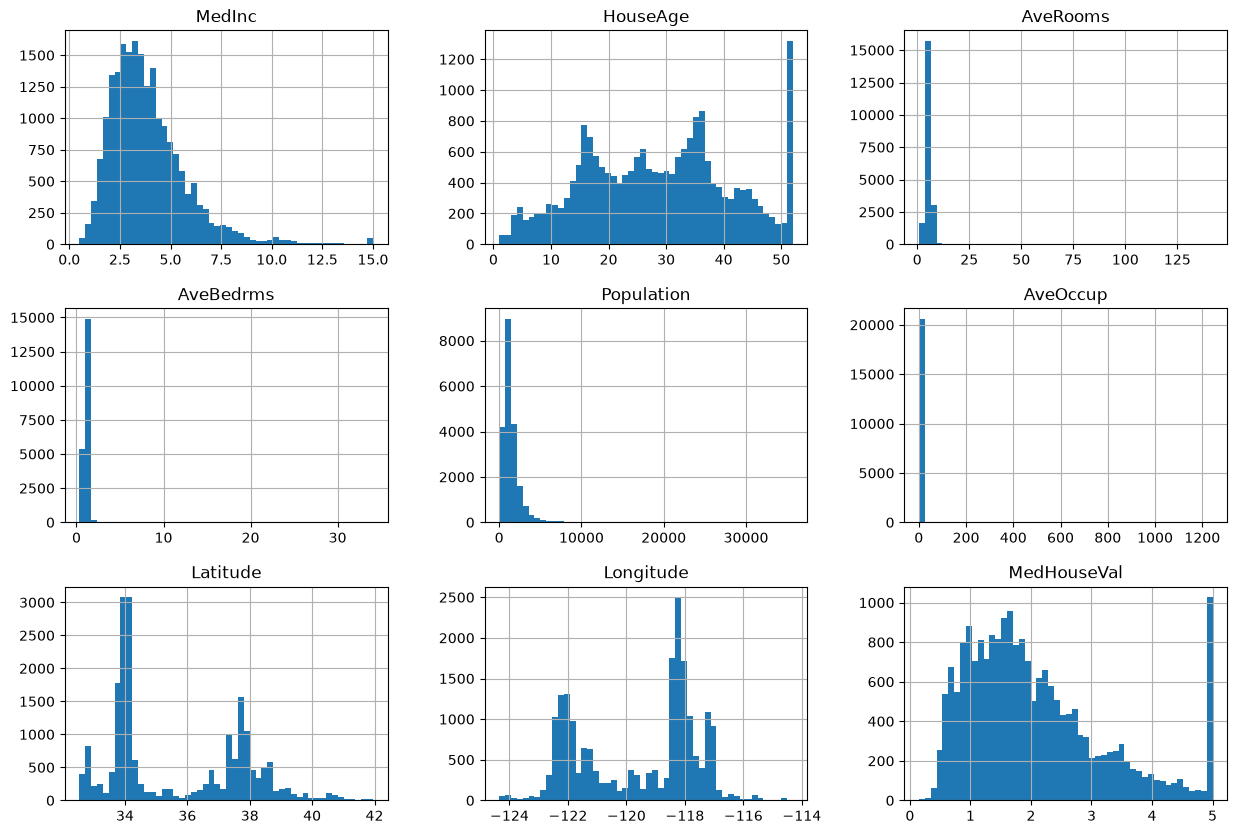

In [4]:
_ = data_df.hist(figsize=[15, 10], bins=50)
plt.show()

The histograms show the shape of each column. Two things stand out: the long right tails of several features, and the pile-up at the top of `MedHouseVal`, which is the \$500,000 cap. `HouseAge` and `MedInc` also pile up at their largest values (52 and 15), which are likely caps in the source data too.

## Part 1: Regression, predicting median house value

**Goal:** predict `MedHouseVal` from the block-group features, and test whether each model is underfitting or overfitting.

A model is *underfitting* when it is too simple to capture the pattern in the data. Its error is high on the data it learned from and on new data. A model is *overfitting* when it memorizes the training data. Its error on the training data keeps falling, but its error on unseen data stops improving or gets worse. The gap between training and test error is the main way to tell the two apart.

This part has six steps. Step 1A fits a simple linear regression by hand. Step 1B removes the capped house values and refits. Step 1C looks at unusually large block groups. Step 1D adds polynomial terms inside a pipeline. Step 1E varies the polynomial degree to diagnose under- and overfitting. Step 1F applies a ridge penalty to see whether it tames the high-degree fits.

### Splitting the data

Steps 1A and 1B split the rows by position: the first 70% train the model and the last 30% test it. This is simple, but a split by position is only fair if the rows are in random order, and nothing guarantees that. The check below compares the two halves.

In [5]:
train_ratio = 0.7
split_idx = int(train_ratio * len(data_df))
train_df = data_df.iloc[:split_idx]   # first 70% of rows
test_df = data_df.iloc[split_idx:]    # last 30% of rows

print(f"Training rows: {len(train_df):,}   Test rows: {len(test_df):,}")
pd.DataFrame({"training half": train_df.mean(), "test half": test_df.mean()}).round(3)

Training rows: 14,447   Test rows: 6,193


,training half,test half
MedInc,3.786,4.069
HouseAge,29.282,27.140
AveRooms,5.407,5.479
AveBedrms,1.107,1.072
Population,1437.069,1398.435
AveOccup,3.035,3.153
Latitude,35.283,36.445
Longitude,-119.116,-120.629
MedHouseVal,1.986,2.262


If the two halves have similar averages, the split is probably fair. If they differ noticeably, the test set describes a different slice of California from the training set, and its scores need extra care.

### Correlations on the training set

Correlation measures how strongly two columns move together, from -1 (opposite directions) to +1 (the same direction). Only the training rows are used here, so the test rows stay untouched.

In [6]:
corr = train_df.corr()
corr["MedHouseVal"].sort_values(ascending=False).to_frame("correlation with MedHouseVal")

,correlation with MedHouseVal
MedHouseVal,1.0000
MedInc,0.6966
AveRooms,0.1379
Longitude,0.0841
HouseAge,0.0709
Population,-0.0189
AveBedrms,-0.0417
AveOccup,-0.0483
Latitude,-0.2419


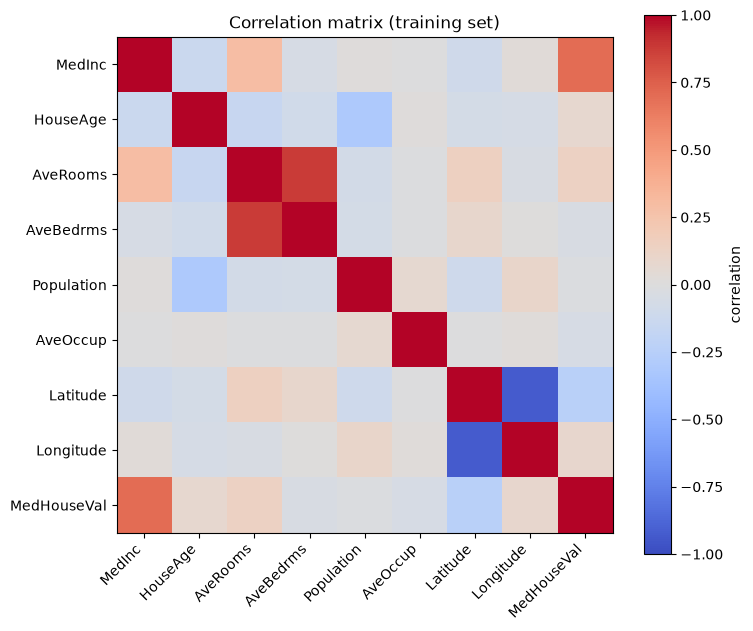

In [7]:
fig, ax = plt.subplots(figsize=[8, 7])
im = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)  # blue = negative, red = positive
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation matrix (training set)")
plt.show()

Read the bottom row of the heatmap, which shows how each feature relates to `MedHouseVal`. The table above gives the same numbers. `MedInc` has the strongest link with house value, which makes it the natural feature to start with, and the link is positive: richer neighborhoods have more expensive houses.

The helper functions below are used throughout Part 1. `fit_simple_linear_regression` computes the line, `regression_metrics` gathers the standard error measures, `plot_fitted_line` shows a fitted line on the training data, and `plot_predicted_vs_actual` draws the predicted-versus-actual check.

In [8]:
def fit_simple_linear_regression(x, y):
    """Least-squares slope and intercept for one feature, from the closed-form formulas."""
    x_mean, y_mean = x.mean(), y.mean()
    S_xx = np.square(x - x_mean).sum() / (len(x) - 1)            # sample variance of x
    S_xy = ((x - x_mean) * (y - y_mean)).sum() / (len(x) - 1)    # sample covariance of x and y
    slope = S_xy / S_xx
    intercept = y_mean - slope * x_mean
    return slope, intercept


def regression_metrics(y_true, y_pred):
    """The standard error metrics for a regression model, as a labeled Series."""
    return pd.Series({
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    })


def plot_fitted_line(ax, x, y, slope, intercept, title):
    """Training data with the fitted line drawn over it."""
    ax.plot(x, y, ".", alpha=0.3, label="training data")
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, intercept + slope * x_line, "-", color="C3", label="fitted line")
    ax.set_xlabel(r"Median income, MedInc (\$10k)")
    ax.set_ylabel(r"Median house value, MedHouseVal (\$100k)")
    ax.set_title(title)
    ax.legend()


def plot_predicted_vs_actual(ax, y_true, y_pred, title):
    """Predicted against actual values. A perfect model would sit on the red line."""
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    ax.plot(y_true, y_pred, ".", alpha=0.3, label="predictions")
    ax.plot([lo, hi], [lo, hi], "r-", label="perfect prediction")
    ax.set_xlabel(r"Actual MedHouseVal (\$100k)")
    ax.set_ylabel(r"Predicted value (\$100k)")
    ax.set_title(title)
    ax.legend()

### 1A: Simple linear regression by hand

We start with a single feature, median income, and fit a straight line, `value = intercept + slope × income`. The least-squares line has a closed-form solution:

$$\text{slope} = \frac{\operatorname{cov}(x, y)}{\operatorname{var}(x)}, \qquad \text{intercept} = \bar{y} - \text{slope}\cdot\bar{x}$$

Here `x` is `MedInc` and `y` is `MedHouseVal`, using the training rows only. One unit of `MedInc` is \$10,000 of income, and one unit of `MedHouseVal` is \$100,000. So the slope says how much house value (in units of \$100,000) goes with each extra \$10,000 of median income.

In [9]:
X_train = train_df["MedInc"].to_numpy()
y_train = train_df["MedHouseVal"].to_numpy()
X_test = test_df["MedInc"].to_numpy()
y_test = test_df["MedHouseVal"].to_numpy()

slope, intercept = fit_simple_linear_regression(X_train, y_train)
print(f"slope = {slope:.4f}, intercept = {intercept:.4f}")

slope = 0.4119, intercept = 0.4262


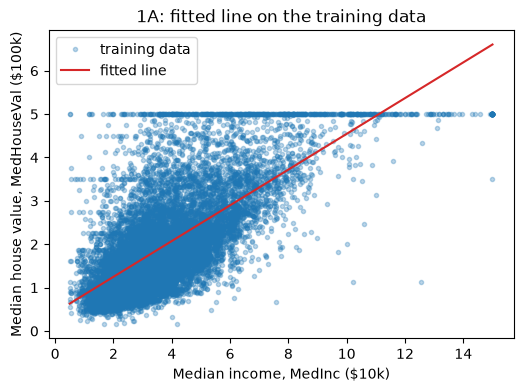

In [10]:
fig, ax = plt.subplots(figsize=[6, 4])
plot_fitted_line(ax, X_train, y_train, slope, intercept, "1A: fitted line on the training data")
plt.show()

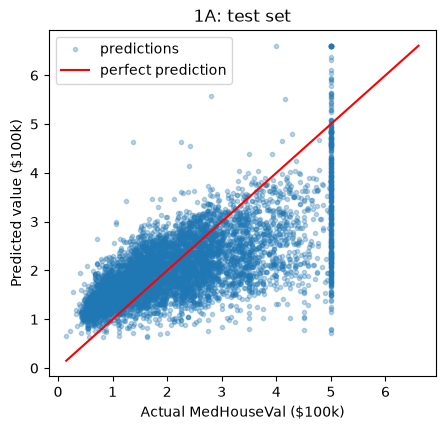

,simple linear regression
MSE,0.8337
RMSE,0.9131
MAE,0.6790
R2,0.4244


In [11]:
y_pred = intercept + slope * X_test   # predictions for the test set

fig, ax = plt.subplots(figsize=[5, 4.5])
plot_predicted_vs_actual(ax, y_test, y_pred, "1A: test set")
plt.show()

regression_metrics(y_test, y_pred).to_frame("simple linear regression")

The predicted-versus-actual plot is the picture to check. Points on the red line are perfect predictions, and the further the cloud sits from the line, the larger the error. Median income alone leaves a lot unexplained, so the points spread widely around the line. The table gives the same story in numbers. R² is the share of the variation in house value that the model explains, so a value well below 1 means much is still unexplained.

### 1B: Removing the capped house values

Block groups at the cap are recorded as \$500,000 even when their true value was higher. The model then learns from numbers that are wrong in a systematic way. A common fix is to drop the capped rows. This step does that, refits the model, and compares the two.

In [12]:
n_capped = (data_df["MedHouseVal"] >= 5).sum()
print(f"Block groups at the $500k cap: {n_capped:,}")

uncapped_df = data_df[data_df["MedHouseVal"] < 5]
split_uncapped = int(train_ratio * len(uncapped_df))
train_df_uncapped = uncapped_df.iloc[:split_uncapped]
test_df_uncapped = uncapped_df.iloc[split_uncapped:]

corr_capped = train_df["MedInc"].corr(train_df["MedHouseVal"])
corr_uncapped = train_df_uncapped["MedInc"].corr(train_df_uncapped["MedHouseVal"])
print(f"Correlation of MedInc with MedHouseVal (training set): "
      f"capped = {corr_capped:.3f}, uncapped = {corr_uncapped:.3f}")

Block groups at the $500k cap: 992
Correlation of MedInc with MedHouseVal (training set): capped = 0.697, uncapped = 0.657


uncapped slope = 0.3923, intercept = 0.4328


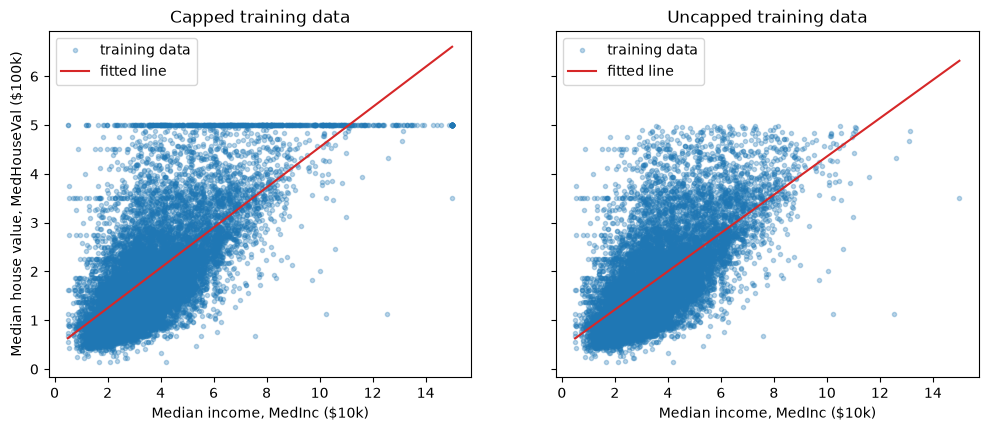

In [13]:
X_train_uncapped = train_df_uncapped["MedInc"].to_numpy()
y_train_uncapped = train_df_uncapped["MedHouseVal"].to_numpy()
X_test_uncapped = test_df_uncapped["MedInc"].to_numpy()
y_test_uncapped = test_df_uncapped["MedHouseVal"].to_numpy()

slope_uncapped, intercept_uncapped = fit_simple_linear_regression(X_train_uncapped, y_train_uncapped)
print(f"uncapped slope = {slope_uncapped:.4f}, intercept = {intercept_uncapped:.4f}")

fig, axes = plt.subplots(1, 2, figsize=[12, 4.5], sharey=True)
plot_fitted_line(axes[0], X_train, y_train, slope, intercept, "Capped training data")
plot_fitted_line(axes[1], X_train_uncapped, y_train_uncapped, slope_uncapped, intercept_uncapped,
                 "Uncapped training data")
axes[1].set_ylabel("")   # the panels share a y-axis, so one label is enough
plt.show()

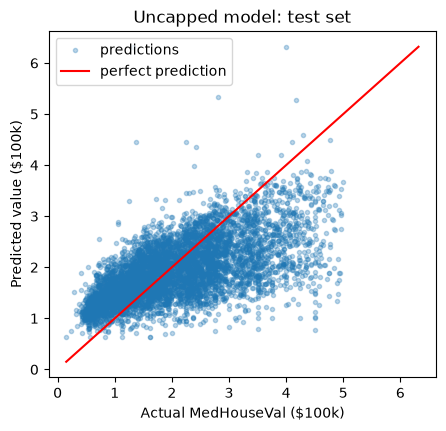

,capped model,uncapped model
MSE,0.8337,0.6508
RMSE,0.9131,0.8067
MAE,0.6790,0.6172
R2,0.4244,0.3588


In [14]:
y_pred_uncapped = intercept_uncapped + slope_uncapped * X_test_uncapped

fig, ax = plt.subplots(figsize=[5, 4.5])
plot_predicted_vs_actual(ax, y_test_uncapped, y_pred_uncapped, "Uncapped model: test set")
plt.show()

pd.concat({
    "capped model": regression_metrics(y_test, y_pred),
    "uncapped model": regression_metrics(y_test_uncapped, y_pred_uncapped),
}, axis=1)

Two things to keep in mind when reading this table. First, the two test sets differ. The uncapped one contains no \$500,000 houses, so the two models are judged on different data. This is a comparison, not a controlled experiment.

Second, RMSE can improve while R² falls. R² is the share of the variation in house value that the model explains. Removing the capped rows also removes some of that variation, so there is less left for the model to explain. When metrics disagree, look at more than one.

### 1C: Unusually large block groups

This step looks at block groups with an unusually high average number of rooms, bedrooms, or occupants: above the 99th percentile on at least one of the three columns. The thresholds are computed on the training rows only.

The original lab stops after this split. A natural next step is to fit a separate model to each group and compare their errors. That is left as an exercise.

In [15]:
limits = train_df[["AveRooms", "AveBedrms", "AveOccup"]].quantile(0.99)
limits.to_frame("99th percentile (training set)").round(2)

,99th percentile (training set)
AveRooms,11.22
AveBedrms,2.30
AveOccup,5.46


309 of 14,447 training block groups are large (2.1%)


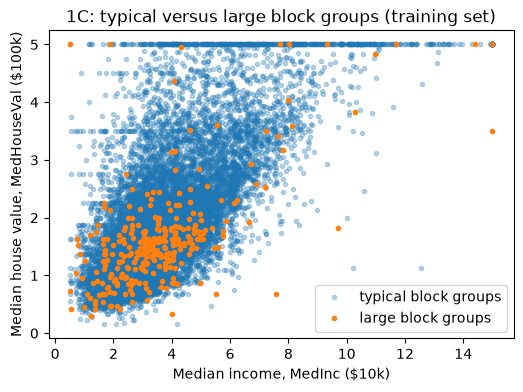

In [16]:
is_large = (
    (train_df["AveRooms"] > limits["AveRooms"])
    | (train_df["AveBedrms"] > limits["AveBedrms"])
    | (train_df["AveOccup"] > limits["AveOccup"])
)
print(f"{is_large.sum():,} of {len(train_df):,} training block groups are large ({is_large.mean():.1%})")

fig, ax = plt.subplots(figsize=[6, 4])
typical = train_df[~is_large]
large = train_df[is_large]
ax.plot(typical["MedInc"], typical["MedHouseVal"], ".", alpha=0.3, label="typical block groups")
ax.plot(large["MedInc"], large["MedHouseVal"], ".", color="C1", label="large block groups")
ax.set_xlabel(r"Median income, MedInc (\$10k)")
ax.set_ylabel(r"Median house value, MedHouseVal (\$100k)")
ax.set_title("1C: typical versus large block groups (training set)")
ax.legend()
plt.show()

Do the large block groups follow the same income-to-value pattern as the rest? Compare where the orange points sit relative to the blue ones.

### 1D: Multiple regression with polynomial features

Now the model uses all eight features at once. The polynomial step adds squared terms and products of features, such as `MedInc` squared and `MedInc` times `Latitude`, so that a linear model can bend. The features are standardized before fitting, because the polynomial terms have very different scales.

Those steps are chained in a scikit-learn `Pipeline`. The pipeline learns the scaling from the training rows only, and it applies the same steps, in the same order, to any new data. The diagram below shows the steps.

Unlike Steps 1A and 1B, this split shuffles the rows first, so the result does not depend on the row order.

In [17]:
def make_poly_model(degree, k_features=None, regressor=None):
    """Polynomial features -> standard scaling -> optional feature selection -> regression."""
    steps = [
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
    ]
    if k_features is not None:
        steps.append(("select", SelectKBest(score_func=f_regression, k=k_features)))
    if regressor is None:
        regressor = LinearRegression(fit_intercept=True)
    steps.append(("regressor", regressor))
    return Pipeline(steps)


X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    feature_df.to_numpy(),
    target_df.to_numpy(),
    train_size=0.7,
    shuffle=True,        # shuffle the rows before splitting
    random_state=1,      # fixed seed, same split as the lab solution
)

model_poly2 = make_poly_model(degree=2)
model_poly2   # displays the pipeline as a diagram

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


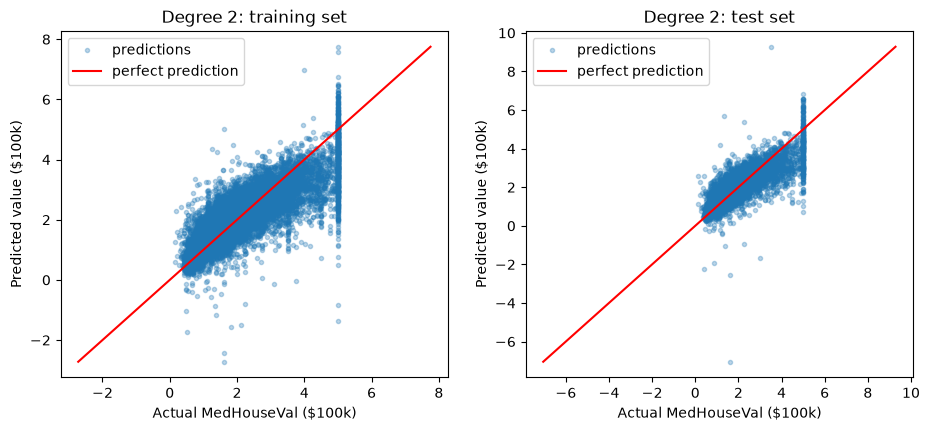

,training set,test set
MSE,0.4177,0.4417
RMSE,0.6463,0.6646
MAE,0.4595,0.4631
R2,0.6880,0.6640


In [18]:
model_poly2.fit(X_train_all, y_train_all)
y_pred_poly_train = model_poly2.predict(X_train_all)
y_pred_poly_test = model_poly2.predict(X_test_all)

fig, axes = plt.subplots(1, 2, figsize=[11, 4.5])
plot_predicted_vs_actual(axes[0], y_train_all, y_pred_poly_train, "Degree 2: training set")
plot_predicted_vs_actual(axes[1], y_test_all, y_pred_poly_test, "Degree 2: test set")
plt.show()

pd.concat({
    "training set": regression_metrics(y_train_all, y_pred_poly_train),
    "test set": regression_metrics(y_test_all, y_pred_poly_test),
}, axis=1)

Compare the two panels and the two columns of the table. A model that does much better on the training rows than on the test rows is starting to memorize them. Step 1E turns this comparison into a systematic test across several polynomial degrees.

### 1E: Under- and overfitting, swept over polynomial degree

This is the central experiment of the regression part. The polynomial degree controls how flexible the model is. Degree 1 is a plain linear model, and higher degrees add more curved terms. For each degree from 1 to 6, the code fits a model and records its training and test RMSE. The gap column shows the difference between them.

Here is how to read the results. Underfitting shows up as high error on both sets, because the model is too simple. A good fit shows test error at its lowest, with training and test error fairly close. Overfitting shows up as training error that keeps falling while test error stops improving or rises. In textbook terms, low degrees have high bias, and high degrees have high variance.

Three cautions apply. First, the degree is chosen by looking at test error. That is fine for diagnosis, but using the test set to pick a final model would leak information. Part 3 shows the cleaner method. Second, degree 6 expands the eight features into about 3,000 columns. It is the slowest fit in this part and can need a gigabyte or more of memory. Third, the highest degrees are numerically fragile. The expanded columns include squared and cubed copies of extreme values, which makes the least-squares problem badly conditioned. The exact test error at degrees 4 to 6 can therefore differ noticeably between computers and library versions, so read the pattern rather than the exact values. Step 1F shows a remedy.

In [19]:
def degree_sweep(X_train, y_train, X_test, y_test, degrees, k_features=None, regressor=None):
    """Fit one model per polynomial degree and return a table of train and test RMSE."""
    rows = []
    for degree in degrees:
        model = make_poly_model(
            degree, k_features, regressor=None if regressor is None else clone(regressor)
        )
        model.fit(X_train, y_train)
        rmse_train = root_mean_squared_error(y_train, model.predict(X_train))
        rmse_test = root_mean_squared_error(y_test, model.predict(X_test))
        rows.append({"degree": degree, "train RMSE": rmse_train,
                     "test RMSE": rmse_test, "test - train": rmse_test - rmse_train})
    return pd.DataFrame(rows).set_index("degree")


degrees = [1, 2, 3, 4, 5, 6]
sweep_all = degree_sweep(X_train_all, y_train_all, X_test_all, y_test_all, degrees)
sweep_selected = degree_sweep(X_train_all, y_train_all, X_test_all, y_test_all, degrees, k_features=8)

pd.concat(
    {"all features": sweep_all, "feature selection (k=8)": sweep_selected},
    axis=1,
).round(4)

all features                        feature selection (k=8)            \
         train RMSE test RMSE test - train              train RMSE test RMSE   
degree                                                                         
1            0.7228    0.7278       0.0050                  0.7228    0.7278   
2            0.6463    0.6646       0.0183                  0.7213    0.7218   
3            0.5847    0.7315       0.1468                  0.7295    0.7304   
4            0.5581    1.0413       0.4832                  0.7341    0.7408   
5            0.5353    7.4069       6.8716                  0.7396    0.7445   
6            0.5263    7.5006       6.9742                  0.7387    0.7432   

                     
       test - train  
degree               
1            0.0050  
2            0.0005  
3            0.0009  
4            0.0067  
5            0.0049  
6            0.0045

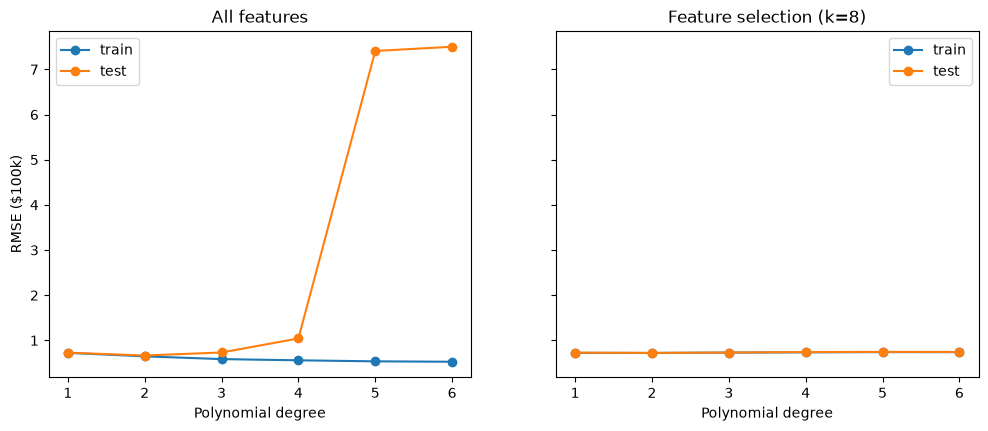

In [20]:
fig, axes = plt.subplots(1, 2, figsize=[12, 4.5], sharey=True)
for ax, table, title in [
    (axes[0], sweep_all, "All features"),
    (axes[1], sweep_selected, "Feature selection (k=8)"),
]:
    ax.plot(table.index, table["train RMSE"], "o-", label="train")
    ax.plot(table.index, table["test RMSE"], "o-", label="test")
    ax.set_xlabel("Polynomial degree")
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel(r"RMSE (\$100k)")
plt.show()

In the left panel, training error falls steadily as the degree rises. If the test error climbs at the highest degrees, that is overfitting in its clearest form. The right panel keeps only the expanded features most related to the target. On the same scale its curves are nearly flat, so the differences between degrees show up only in the table above. Stability is what feature selection buys, but it is not the same as accuracy. Compare the lowest point on each curve, because a flatter curve is not automatically a more accurate one.

### 1F: A remedy, ridge regularization

The high-degree fits fail for a specific reason. Ordinary least squares tries to match every training row as closely as it can. With thousands of correlated polynomial columns, it can settle on very large positive and negative coefficients that cancel out on the training rows but do not carry over to new rows. Ridge regression adds a penalty on the size of the coefficients. The strength of the penalty is set by `alpha`: larger values give smoother, more constrained models. Here `alpha = 1` is a starting point, not a tuned choice. Tuning it with cross-validation, as Part 3 does for its parameters, is a natural next step.

In [21]:
ridge_sweep = degree_sweep(
    X_train_all, y_train_all, X_test_all, y_test_all, degrees, regressor=Ridge(alpha=1.0)
)
pd.concat(
    {"linear regression": sweep_all, "ridge, alpha = 1": ridge_sweep},
    axis=1,
).round(4)

linear regression                        ridge, alpha = 1            \
              train RMSE test RMSE test - train       train RMSE test RMSE   
degree                                                                       
1                 0.7228    0.7278       0.0050           0.7228    0.7277   
2                 0.6463    0.6646       0.0183           0.6649    0.6737   
3                 0.5847    0.7315       0.1468           0.6248    0.6465   
4                 0.5581    1.0413       0.4832           0.6057    0.6590   
5                 0.5353    7.4069       6.8716           0.5958    0.6633   
6                 0.5263    7.5006       6.9742           0.5874    0.6867   

                     
       test - train  
degree               
1            0.0050  
2            0.0088  
3            0.0217  
4            0.0534  
5            0.0675  
6            0.0993

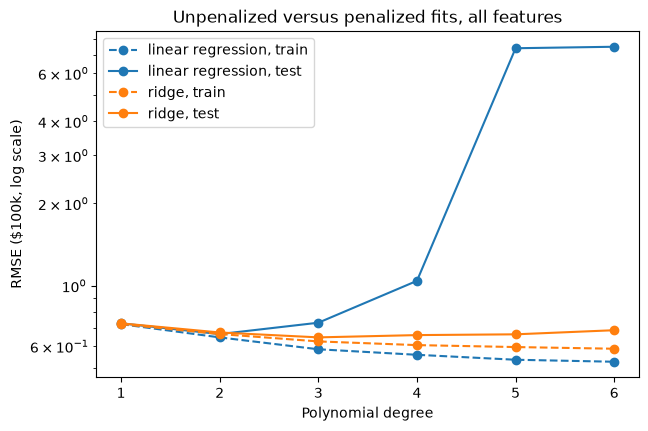

In [22]:
fig, ax = plt.subplots(figsize=[7, 4.5])
for table, name, color in [(sweep_all, "linear regression", "C0"), (ridge_sweep, "ridge", "C1")]:
    ax.plot(table.index, table["train RMSE"], "o--", color=color, label=f"{name}, train")
    ax.plot(table.index, table["test RMSE"], "o-", color=color, label=f"{name}, test")
ax.set_yscale("log")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel(r"RMSE (\$100k, log scale)")
ax.set_title("Unpenalized versus penalized fits, all features")
ax.legend()
plt.show()

Read the plot on its log scale, because the unpenalized errors can run into the thousands at high degrees. The penalty trades a little training accuracy for steadier predictions on new rows. Its training error is slightly higher than the unpenalized training error, but its test error stays much closer to its training error. Where the unpenalized test error escapes upward, the penalized test error usually stays near its low-degree level.

### What to take from Part 1

Four ideas carry forward into the rest of the notebook. Compare training and test error side by side, because the gap is the diagnostic. Check the data for capped or extreme values before blaming the model. When a model overfits, a penalty on its coefficients is often the first remedy to try. And use the test set to diagnose a model, but choose its settings without it.

## Part 2: Binary classification, tuning the decision threshold

**Goal:** optimize the ROC curve.

The target becomes a yes-or-no question: is the median house value above \$250,000? A classifier does not answer yes or no directly. Logistic regression outputs a probability for each block group, and a threshold turns that probability into a decision. The default threshold is 0.5, but nothing requires it. A lower threshold catches more of the expensive houses and raises more false alarms. A higher threshold does the opposite. The ROC curve shows that trade-off at every threshold at once, and the area under it (AUC) summarizes the classifier in one number.

The steps are to fit the model, read the results at the default threshold, study the ROC curve, and choose a better threshold.

### The target and the split

In [23]:
BINARY_NAMES = ["At or below $250k", "Above $250k"]

def binary_metrics(y_true, y_pred):
    """Accuracy, precision, recall and F1, with class 1 as the positive class."""
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    })


def plot_confusion_matrix(y_true, y_pred, display_labels, title, ax):
    """Confusion matrix drawn on `ax`. Rows are true classes and columns are predicted classes."""
    cm = confusion_matrix(y_true, y_pred)
    labels = [label.replace("$", r"\$") for label in display_labels]  # stop matplotlib reading $ as maths
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)
    return cm


y_binary = (target_df > 2.5).astype(int)   # 1 = above $250,000 (MedHouseVal > 2.5), 0 = otherwise
print(f"At or below $250k: {(y_binary == 0).sum():,} block groups")
print(f"Above $250k:       {(y_binary == 1).sum():,} block groups")

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    feature_df.to_numpy(),
    y_binary.to_numpy(),
    train_size=0.7,
    shuffle=True,
    random_state=0,   # same split as the lab solution, so results can be compared
)
print(f"\nTraining set: {len(X_train_bin):,} rows   Test set: {len(X_test_bin):,} rows")

At or below $250k: 14,858 block groups
Above $250k:       5,782 block groups

Training set: 14,447 rows   Test set: 6,193 rows


### Logistic regression at the default threshold

The confusion matrix counts the four possible outcomes:

| | Predicted at or below \$250k | Predicted above \$250k |
|---|---|---|
| Actually at or below \$250k | true negative | false positive |
| Actually above \$250k | false negative | true positive |

In [24]:
logreg = LogisticRegression(max_iter=10000)   # more iterations so the solver converges
logreg.fit(X_train_bin, y_train_bin)

pd.DataFrame(
    logreg.predict_proba(X_test_bin[:5]),
    columns=["P(class 0)", "P(class 1)"],
).round(3)

,P(class 0),P(class 1)
0,0.796,0.204
1,0.418,0.582
2,0.937,0.063
3,0.995,0.005
4,0.210,0.790


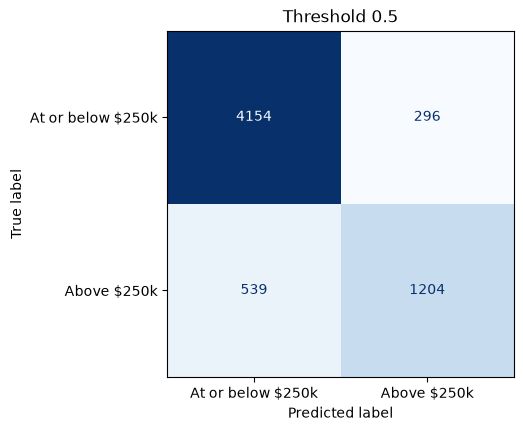

True negatives: 4,154   False positives: 296
False negatives: 539  True positives: 1,204

Accuracy:  86.52% of all predictions are correct
Precision: 80.27% of 'above $250k' predictions are right
Recall:    69.08% of the truly 'above $250k' houses are found
F1:        74.25%, the balance of precision and recall

                   precision    recall  f1-score   support

At or below $250k       0.89      0.93      0.91      4450
      Above $250k       0.80      0.69      0.74      1743

         accuracy                           0.87      6193
        macro avg       0.84      0.81      0.83      6193
     weighted avg       0.86      0.87      0.86      6193



In [25]:
y_pred_proba = logreg.predict_proba(X_test_bin)   # column 1 is P(class 1), the probability of "above $250k"
y_pred = logreg.predict(X_test_bin)                # class 1 when P(class 1) >= 0.5

fig, ax = plt.subplots(figsize=[5.5, 4.5])
cm = plot_confusion_matrix(y_test_bin, y_pred, BINARY_NAMES, "Threshold 0.5", ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
default_scores = binary_metrics(y_test_bin, y_pred)
print(f"True negatives: {tn:,}   False positives: {fp:,}")
print(f"False negatives: {fn:,}  True positives: {tp:,}\n")
print(f"Accuracy:  {default_scores['accuracy']:.2%} of all predictions are correct")
print(f"Precision: {default_scores['precision']:.2%} of 'above $250k' predictions are right")
print(f"Recall:    {default_scores['recall']:.2%} of the truly 'above $250k' houses are found")
print(f"F1:        {default_scores['F1']:.2%}, the balance of precision and recall\n")
print(classification_report(y_test_bin, y_pred, target_names=BINARY_NAMES))

Precision asks: of the houses the model calls expensive, how many really are? Recall asks: of the houses that really are expensive, how many did the model find? Accuracy can look respectable even when the model misses many expensive houses, because the two classes are not the same size. That is why the per-class rows of the report matter.

### The ROC curve and AUC

The ROC curve is built by sweeping the threshold from high to low. At each step it records two rates: the true positive rate, the share of expensive houses caught, and the false positive rate, the share of other houses wrongly flagged as expensive. A perfect classifier reaches the top-left corner. A random guesser runs along the diagonal.

The AUC is the probability that a randomly chosen expensive house gets a higher score than a randomly chosen other house. A random guesser scores 0.5, and values closer to 1 mean the classifier ranks houses better.

In [26]:
fpr, tpr, thresholds = roc_curve(y_test_bin, y_pred_proba[:, 1], pos_label=1)
auc = roc_auc_score(y_test_bin, y_pred_proba[:, 1])
print(f"AUC = {auc:.3f}")

AUC = 0.921


### Choosing a better threshold

The best threshold depends on what each kind of mistake costs. This notebook uses a simple rule: pick the ROC point closest to the ideal corner, where the false positive rate is 0 and the true positive rate is 1, measured as straight-line distance. Youden's J statistic, which picks the point that maximizes the true positive rate minus the false positive rate, is a common alternative and often gives a similar threshold.

Chosen threshold: 0.3380 (FPR = 0.141, TPR = 0.823)


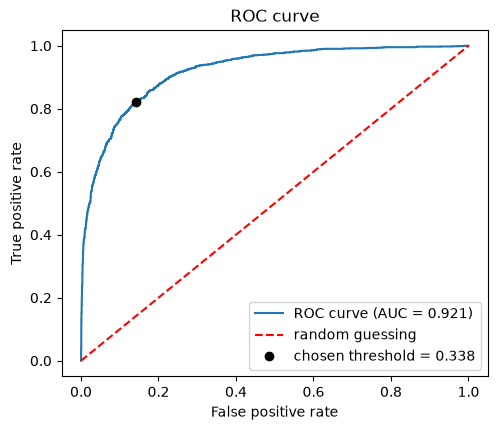

In [27]:
distance_to_corner = np.sqrt(fpr ** 2 + (1 - tpr) ** 2)
best_idx = np.argmin(distance_to_corner)
best_thres = thresholds[best_idx]
print(f"Chosen threshold: {best_thres:.4f} (FPR = {fpr[best_idx]:.3f}, TPR = {tpr[best_idx]:.3f})")

fig, ax = plt.subplots(figsize=[5.5, 4.5])
ax.plot(fpr, tpr, "-", label=f"ROC curve (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "r--", label="random guessing")
ax.plot(fpr[best_idx], tpr[best_idx], "ko", label=f"chosen threshold = {best_thres:.3f}")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve")
ax.legend()
plt.show()

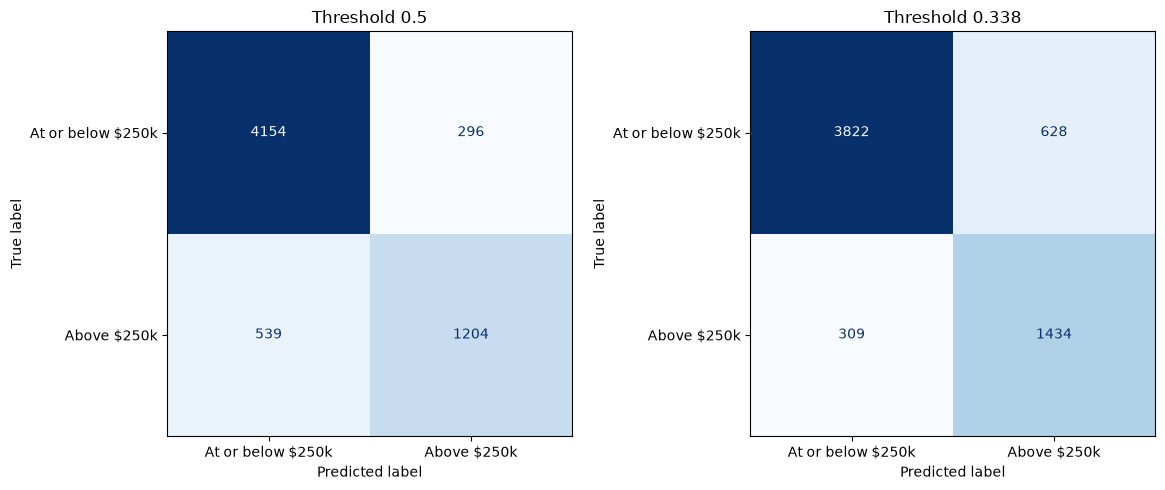

Scores in percent; change is in percentage points


,threshold 0.5,threshold 0.338,change
accuracy,86.52,84.87,-1.65
precision,80.27,69.54,-10.72
recall,69.08,82.27,13.20
F1,74.25,75.37,1.12


In [28]:
y_pred_tuned = (y_pred_proba[:, 1] >= best_thres).astype(int)

fig, axes = plt.subplots(1, 2, figsize=[12, 5])
plot_confusion_matrix(y_test_bin, y_pred, BINARY_NAMES, "Threshold 0.5", axes[0])
plot_confusion_matrix(y_test_bin, y_pred_tuned, BINARY_NAMES, f"Threshold {best_thres:.3f}", axes[1])
plt.tight_layout()
plt.show()

tuned_label = f"threshold {best_thres:.3f}"
comparison_2 = pd.concat({
    "threshold 0.5": default_scores,
    tuned_label: binary_metrics(y_test_bin, y_pred_tuned),
}, axis=1)
comparison_2["change"] = comparison_2[tuned_label] - comparison_2["threshold 0.5"]
print("Scores in percent; change is in percentage points")
(comparison_2 * 100).round(2)

In [29]:
print(classification_report(y_test_bin, y_pred_tuned, target_names=BINARY_NAMES))

                   precision    recall  f1-score   support

At or below $250k       0.93      0.86      0.89      4450
      Above $250k       0.70      0.82      0.75      1743

         accuracy                           0.85      6193
        macro avg       0.81      0.84      0.82      6193
     weighted avg       0.86      0.85      0.85      6193



Read the comparison as a trade-off. The tuned threshold usually catches more of the expensive houses, so recall rises, and it is less often right when it calls a house expensive, so precision usually falls. Whether that is a good trade depends on the problem. The F1 score balances the two, but it treats them as equally important, which is not always what the problem needs.

Caveat: the threshold was chosen by looking at the test set, so the tuned scores are slightly optimistic. The stricter workflow picks the threshold on a separate validation split and reports the test set once at the end. Cross-validation, used in Part 3, is one way to do that.

## Part 3: Multi-class classification, features and parameters

**Goal:** improve performance through feature selection and parameter tuning.

Each block group now falls into one of three price bands: below \$100,000, between \$100,000 and \$250,000, or above \$250,000. The model is K-nearest neighbors (KNN). To classify a block group, KNN finds the *k* most similar training block groups and takes a majority vote. Two choices control how well it works: which features define "similar", and how many neighbors vote. This part explores both.

The bands are not the same size, so accuracy alone can flatter a model that does well on the largest band and poorly on the others. The main score here is macro F1. It computes the F1 score for each band and averages the three with equal weight.

The steps are a KNN baseline on all features, a linear support vector machine for comparison, KNN after feature selection, a grid search over the number of features and the number of neighbors, and a final comparison on the test set.

### Step 1: Price bands and the split

In [30]:
def price_band(value):
    """0 = below $100k, 1 = $100k to $250k, 2 = above $250k (MedHouseVal is in $100k units)."""
    if value < 1:
        return 0
    if value <= 2.5:
        return 1
    return 2


BAND_NAMES = ["Below $100k", "$100k to $250k", "Above $250k"]

y_band = target_df.apply(price_band)
for band, name in enumerate(BAND_NAMES):
    print(f"{name:<16} {(y_band == band).sum():>7,} block groups")

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    feature_df.to_numpy(),
    y_band.to_numpy(),
    train_size=0.7,
    shuffle=True,
    random_state=0,
)
print(f"\nTraining set: {len(X_train_multi):,} rows   Test set: {len(X_test_multi):,} rows")

Below $100k        3,596 block groups
$100k to $250k    11,262 block groups
Above $250k        5,782 block groups

Training set: 14,447 rows   Test set: 6,193 rows


### Step 2: KNN baseline on all features

KNN measures the distance between block groups, so the units matter. Population is counted in the thousands, while median income runs from about 0.5 to 15. Without scaling, population would dominate the distance and income would barely count. The `StandardScaler` puts every feature on the same footing, with mean 0 and standard deviation 1 in the training data.

In [31]:
knn_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski", p=2)),
])
knn_clf.fit(X_train_multi, y_train_multi)

X_train_scaled = knn_clf.named_steps["scaler"].transform(X_train_multi)
is_standardized = (
    np.allclose(X_train_scaled.mean(axis=0), 0) and np.allclose(X_train_scaled.std(axis=0), 1)
)
print("Scaled training features have mean 0 and standard deviation 1:", is_standardized)

y_pred_knn = knn_clf.predict(X_test_multi)
pd.DataFrame(
    knn_clf.predict_proba(X_test_multi[:5]),
    columns=["band 0", "band 1", "band 2"],
).round(2)

Scaled training features have mean 0 and standard deviation 1: True


,band 0,band 1,band 2
0,0.0,1.0,0.0
1,0.0,0.6,0.4
2,0.2,0.8,0.0
3,1.0,0.0,0.0
4,0.0,0.2,0.8


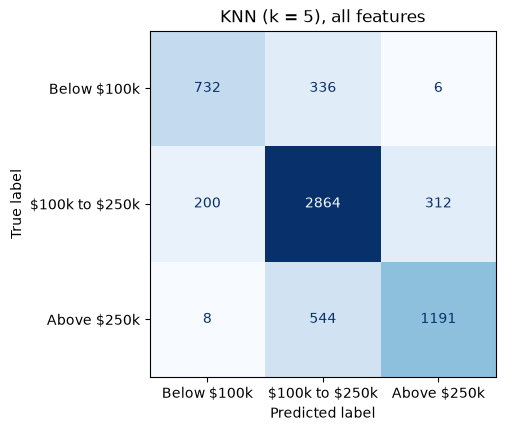

                precision    recall  f1-score   support

   Below $100k       0.78      0.68      0.73      1074
$100k to $250k       0.76      0.85      0.80      3376
   Above $250k       0.79      0.68      0.73      1743

      accuracy                           0.77      6193
     macro avg       0.78      0.74      0.75      6193
  weighted avg       0.77      0.77      0.77      6193



In [32]:
fig, ax = plt.subplots(figsize=[5.5, 4.5])
plot_confusion_matrix(y_test_multi, y_pred_knn, BAND_NAMES, "KNN (k = 5), all features", ax)
plt.show()
print(classification_report(y_test_multi, y_pred_knn, target_names=BAND_NAMES))

With five neighbors, each probability is a multiple of 0.2: it is the share of the five nearest training block groups that belong to each band. In the confusion matrix, check whether the errors fall mostly between neighboring bands. Because the bands are ordered, a house near a boundary is the hardest to place, so that is the pattern to expect.

### Step 3: A linear support vector machine for comparison

A linear support vector machine (SVM) separates the bands with straight boundaries, called hyperplanes. An SVM does not produce probabilities by itself, so `CalibratedClassifierCV` converts its scores into probabilities. An older option, `SVC(probability=True)`, is deprecated in recent scikit-learn releases. Calibration refits the SVM internally, which is why this is usually the slowest step in this part.

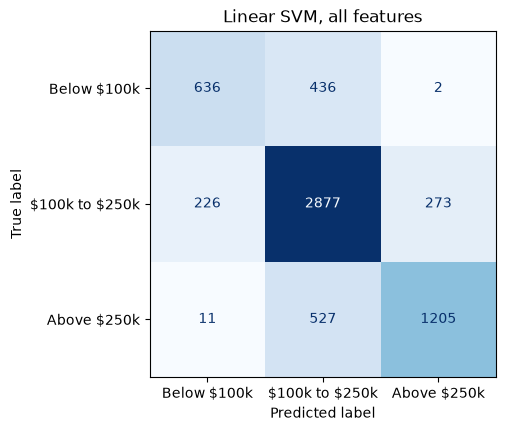

                precision    recall  f1-score   support

   Below $100k       0.73      0.59      0.65      1074
$100k to $250k       0.75      0.85      0.80      3376
   Above $250k       0.81      0.69      0.75      1743

      accuracy                           0.76      6193
     macro avg       0.76      0.71      0.73      6193
  weighted avg       0.76      0.76      0.76      6193



In [33]:
svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", CalibratedClassifierCV(SVC(kernel="linear", random_state=0), ensemble=False)),
])
svm_clf.fit(X_train_multi, y_train_multi)

y_pred_svm = svm_clf.predict(X_test_multi)
y_pred_proba_svm = svm_clf.predict_proba(X_test_multi)

fig, ax = plt.subplots(figsize=[5.5, 4.5])
plot_confusion_matrix(y_test_multi, y_pred_svm, BAND_NAMES, "Linear SVM, all features", ax)
plt.show()
print(classification_report(y_test_multi, y_pred_svm, target_names=BAND_NAMES))

### Step 4: Feature selection

Feature selection asks which inputs carry the most information about the target. `SelectKBest` with `f_classif` scores each feature with an ANOVA F-test. A high score means the feature's average differs a lot between the three bands, compared with how much the values spread within each band. Keeping only the top scorers focuses KNN's distances on the most informative features.

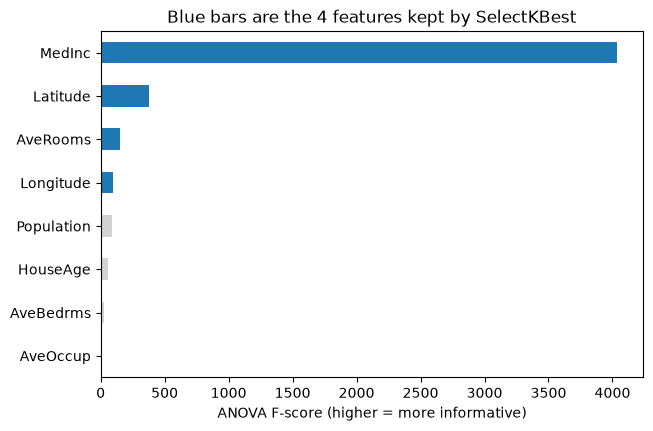

                precision    recall  f1-score   support

   Below $100k       0.73      0.70      0.72      1074
$100k to $250k       0.78      0.83      0.80      3376
   Above $250k       0.80      0.73      0.76      1743

      accuracy                           0.78      6193
     macro avg       0.77      0.75      0.76      6193
  weighted avg       0.78      0.78      0.78      6193



In [34]:
knn_sel_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=4)),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski", p=2)),
])
knn_sel_clf.fit(X_train_multi, y_train_multi)

selector = knn_sel_clf.named_steps["select"]
f_scores = pd.Series(selector.scores_, index=feature_df.columns)
kept_features = feature_df.columns[selector.get_support()]

ranked = f_scores.sort_values()
bar_colors = ["C0" if name in kept_features else "lightgray" for name in ranked.index]
fig, ax = plt.subplots(figsize=[7, 4.5])
ranked.plot.barh(ax=ax, color=bar_colors)
ax.set_xlabel("ANOVA F-score (higher = more informative)")
ax.set_title("Blue bars are the 4 features kept by SelectKBest")
plt.show()

y_pred_knn_sel = knn_sel_clf.predict(X_test_multi)
print(classification_report(y_test_multi, y_pred_knn_sel, target_names=BAND_NAMES))

Income is the strongest single signal in this dataset, so `MedInc` should sit at the top of the ranking. The highlighted bars are the four features kept for this model. Whether the reduced model does better or worse than the full one is what the comparison table at the end is for.

### Step 5: Tuning with grid search and cross-validation

The choices of four features and five neighbors were made by hand, and nothing says they are the best ones. A grid search tries every combination of values in the grid. For each combination it runs 5-fold cross-validation on the training rows: the rows are split into five folds, the model is trained on four folds and scored on the fifth, and the five scores are averaged. Every score comes from training data, so the test set stays untouched.

The pipeline matters here. Scaling and feature selection are part of the pipeline, so they are refitted inside every fold. That keeps information from the held-out fold from leaking into training.

In [35]:
param_grid = {
    "select__k": list(range(2, 9)),                 # keep between 2 and 8 of the 8 features
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],   # odd values are common for voting
}
grid = GridSearchCV(
    estimator=knn_sel_clf,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",   # macro F1 gives each band equal weight
)
grid.fit(X_train_multi, y_train_multi)

print("Best parameters:", grid.best_params_)
print(f"Best mean cross-validated macro F1: {grid.best_score_:.3f}")
best_features = feature_df.columns[grid.best_estimator_.named_steps["select"].get_support()]
print("Features kept by the best model:", ", ".join(best_features))

Best parameters: {'knn__n_neighbors': 11, 'select__k': 8}
Best mean cross-validated macro F1: 0.743
Features kept by the best model: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude


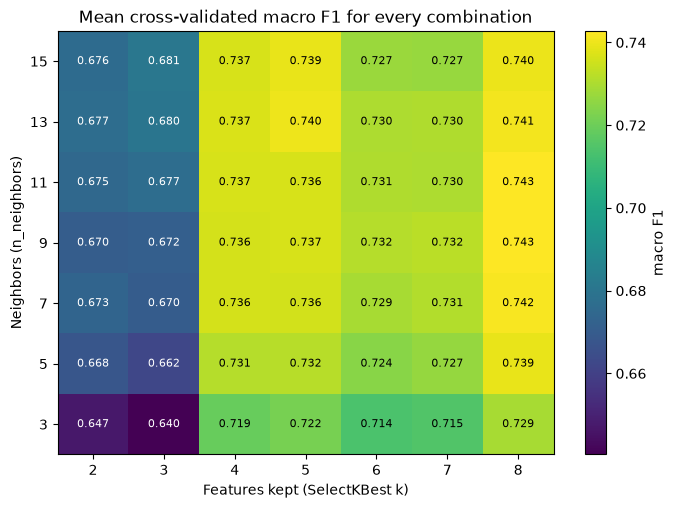

In [36]:
results = pd.DataFrame(grid.cv_results_)
score_grid = results.pivot(
    index="param_knn__n_neighbors",
    columns="param_select__k",
    values="mean_test_score",
)
values = score_grid.to_numpy()
midpoint = (values.min() + values.max()) / 2

fig, ax = plt.subplots(figsize=[8, 5.5])
im = ax.imshow(values, cmap="viridis", origin="lower", aspect="auto")
ax.set_xticks(range(score_grid.shape[1]))
ax.set_xticklabels(score_grid.columns)
ax.set_yticks(range(score_grid.shape[0]))
ax.set_yticklabels(score_grid.index)
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if values[i, j] < midpoint else "black")
ax.set_xlabel("Features kept (SelectKBest k)")
ax.set_ylabel("Neighbors (n_neighbors)")
ax.set_title("Mean cross-validated macro F1 for every combination")
fig.colorbar(im, ax=ax, label="macro F1")
plt.show()

Read the heatmap for its overall shape, not only for the best cell. A broad region of similar scores means many settings work about equally well. A single bright cell surrounded by weaker ones means the result depends on one specific setting, which may not carry over to new data as well. If the best feature count is the largest value in the grid, the search is saying that dropping features did not help on this dataset.

### Step 6: Final comparison on the test set

The search never used the test set, so the tuned model's test score is an honest estimate. The table below sets the tuned model beside the models from earlier steps. Those earlier scores were printed for comparison only; nothing was chosen from them.

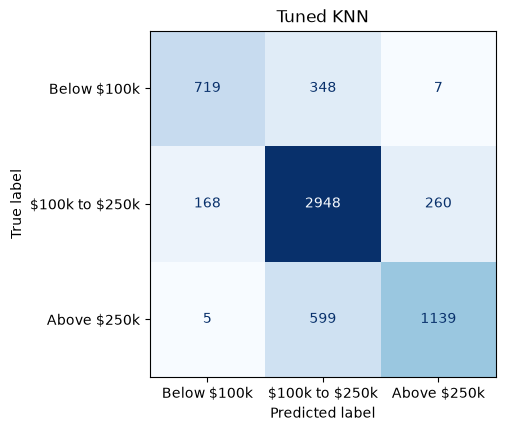

                precision    recall  f1-score   support

   Below $100k       0.81      0.67      0.73      1074
$100k to $250k       0.76      0.87      0.81      3376
   Above $250k       0.81      0.65      0.72      1743

      accuracy                           0.78      6193
     macro avg       0.79      0.73      0.76      6193
  weighted avg       0.78      0.78      0.77      6193



,accuracy,macro F1
model,,
"KNN, all features, k=5",0.773,0.755
"Linear SVM, all features",0.762,0.733
"KNN, 4 best features, k=5",0.778,0.761
Tuned KNN (grid search),0.776,0.755


In [37]:
y_pred_tuned = grid.predict(X_test_multi)   # GridSearchCV refit the best pipeline on all training rows

fig, ax = plt.subplots(figsize=[5.5, 4.5])
plot_confusion_matrix(y_test_multi, y_pred_tuned, BAND_NAMES, "Tuned KNN", ax)
plt.show()
print(classification_report(y_test_multi, y_pred_tuned, target_names=BAND_NAMES))

model_predictions = {
    "KNN, all features, k=5": y_pred_knn,
    "Linear SVM, all features": y_pred_svm,
    "KNN, 4 best features, k=5": y_pred_knn_sel,
    "Tuned KNN (grid search)": y_pred_tuned,
}
pd.DataFrame([
    {
        "model": name,
        "accuracy": accuracy_score(y_test_multi, pred),
        "macro F1": f1_score(y_test_multi, pred, average="macro"),
    }
    for name, pred in model_predictions.items()
]).set_index("model").round(3)

Compare the rows with care. A difference of about one point of macro F1 on a test set of roughly 6,000 rows is within normal variation. The tuned model's advantage is methodological: its settings were chosen without looking at the test set. Whether it also scores highest on this particular split is a separate question, and the answer may be no.

## Limitations and next steps

Some choices here are simplifications made for learning. The thresholds and polynomial degrees in Parts 1 and 2 were judged by looking at test scores, so those numbers are a little optimistic. The clean workflow sets aside a validation split, or uses cross-validation as in Part 3, for every decision, and reports the test set once at the end.

Steps 1A and 1B also split the rows by position. A random split is usually the safer default, and the later steps use one.

Next steps worth trying: choose the ridge penalty with cross-validation; try clipping or transforming the most extreme features before expanding them; fit a separate model to each group of large block groups from Step 1C; compare more classifiers on the three-band problem; and repeat the splits with cross-validation to measure how much the scores vary.

## Source

The data is loaded through scikit-learn, which takes it from Pace, R. Kelley and Ronald Barry (1997), "Sparse Spatial Autoregressions," *Statistics & Probability Letters*. The notebook started as lab exercises and was reorganized into this structure.